In [1]:
import sys

print("Python Path:", sys.executable)
print("Jupyter is ready!")

Python Path: c:\Users\Ayush Saha\OneDrive\Desktop\Explainable_CVD_Prediction\.venv\Scripts\python.exe
Jupyter is ready!


In [2]:
import pandas as pd

df = pd.read_csv("../dataset/heart.csv")

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
print("DATASET OVERVIEW")
print("=" * 40)

print("Dataset Shape:", df.shape)
print("Total Records:", len(df))
print("Total Features:", len(df.columns))

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

DATASET OVERVIEW
Dataset Shape: (1025, 14)
Total Records: 1025
Total Features: 14

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [4]:
print("MISSING VALUE ANALYSIS")
print("=" * 40)

print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

MISSING VALUE ANALYSIS
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total Missing Values: 0


In [5]:
print("DUPLICATE RECORD ANALYSIS")
print("=" * 40)

print("Total Rows:", len(df))
print("Duplicate Rows:", df.duplicated().sum())
print("Unique Rows:", len(df.drop_duplicates()))

DUPLICATE RECORD ANALYSIS
Total Rows: 1025
Duplicate Rows: 723
Unique Rows: 302


In [6]:
print("TARGET DISTRIBUTION")
print("=" * 40)

print(df["target"].value_counts())

print("\nTarget Percentage:")
print(df["target"].value_counts(normalize=True) * 100)

TARGET DISTRIBUTION
target
1    526
0    499
Name: count, dtype: int64

Target Percentage:
target
1    51.317073
0    48.682927
Name: proportion, dtype: float64


In [7]:
print("DUPLICATE FREQUENCY ANALYSIS")
print("=" * 45)

duplicate_frequency = df.value_counts()

print("Number of unique records:",
      len(duplicate_frequency))

print("\nFrequency of repeated records:")
print(duplicate_frequency.value_counts().sort_index())

print("\nTop 10 most repeated records:")
print(duplicate_frequency.head(10))

DUPLICATE FREQUENCY ANALYSIS
Number of unique records: 302

Frequency of repeated records:
count
3    187
4    114
8      1
Name: count, dtype: int64

Top 10 most repeated records:
age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  ca  thal  target
38   1    2   138       175   0    1        173      0      0.0      2      4   2     1         8
52   1    0   125       212   0    1        168      0      1.0      2      2   3     0         4
53   1    0   140       203   1    0        155      1      3.1      0      0   3     0         4
70   1    0   145       174   0    1        125      1      2.6      0      0   3     0         4
61   1    0   148       203   0    1        161      0      0.0      2      1   3     0         4
58   1    0   114       318   0    2        140      0      4.4      0      3   1     0         4
55   1    0   160       289   0    0        145      1      0.8      1      1   3     0         4
46   1    0   120       249   0    0    

In [8]:
print("TARGET CONSISTENCY CHECK")
print("=" * 45)

features = df.drop(columns=["target"])

label_counts = features.copy()
label_counts["target"] = df["target"]

conflicts = label_counts.groupby(
    list(features.columns)
)["target"].nunique()

print("Conflicting feature combinations:",
      (conflicts > 1).sum())

print("Consistent feature combinations:",
      (conflicts == 1).sum())

TARGET CONSISTENCY CHECK
Conflicting feature combinations: 0
Consistent feature combinations: 302


In [9]:
# Create a copy without duplicate records

df_clean = df.drop_duplicates().reset_index(drop=True)

print("DATA CLEANING SUMMARY")
print("=" * 40)

print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

print("Removed Records:", len(df) - len(df_clean))

print("Remaining Duplicates:",
      df_clean.duplicated().sum())

DATA CLEANING SUMMARY
Original Dataset: (1025, 14)
Cleaned Dataset: (302, 14)
Removed Records: 723
Remaining Duplicates: 0


In [10]:
print("CLEANED TARGET DISTRIBUTION")
print("=" * 40)

print(df_clean["target"].value_counts())

print("\nTarget Percentage:")

print(
    df_clean["target"]
    .value_counts(normalize=True) * 100
)

CLEANED TARGET DISTRIBUTION
target
1    164
0    138
Name: count, dtype: int64

Target Percentage:
target
1    54.304636
0    45.695364
Name: proportion, dtype: float64


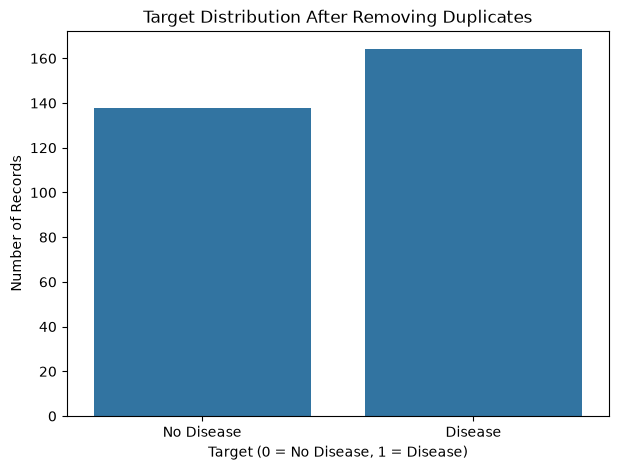

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="target"
)

plt.title("Target Distribution After Removing Duplicates")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Records")

plt.xticks([0, 1], ["No Disease", "Disease"])

plt.show()

In [12]:
print("DESCRIPTIVE STATISTICAL ANALYSIS")
print("=" * 50)

df_clean.describe().T

DESCRIPTIVE STATISTICAL ANALYSIS


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682119,0.466426,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
trestbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149007,0.356686,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
thalach,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.327815,0.470196,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2


In [13]:
numerical_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical Features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


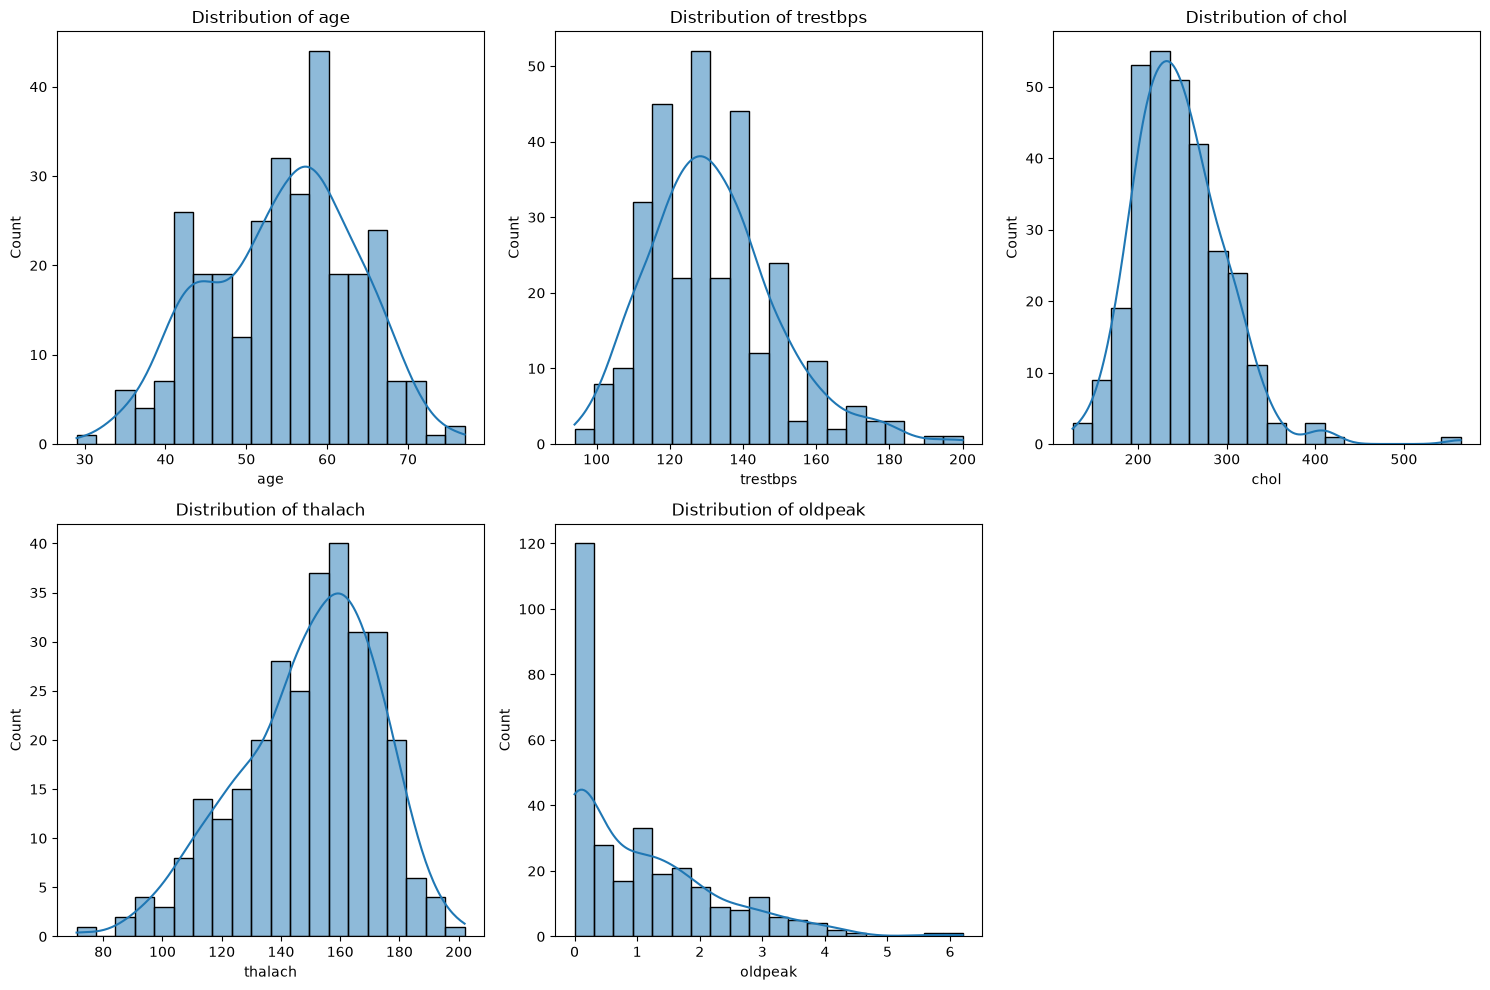

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_features, 1):

    plt.subplot(2, 3, i)

    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        bins=20
    )

    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

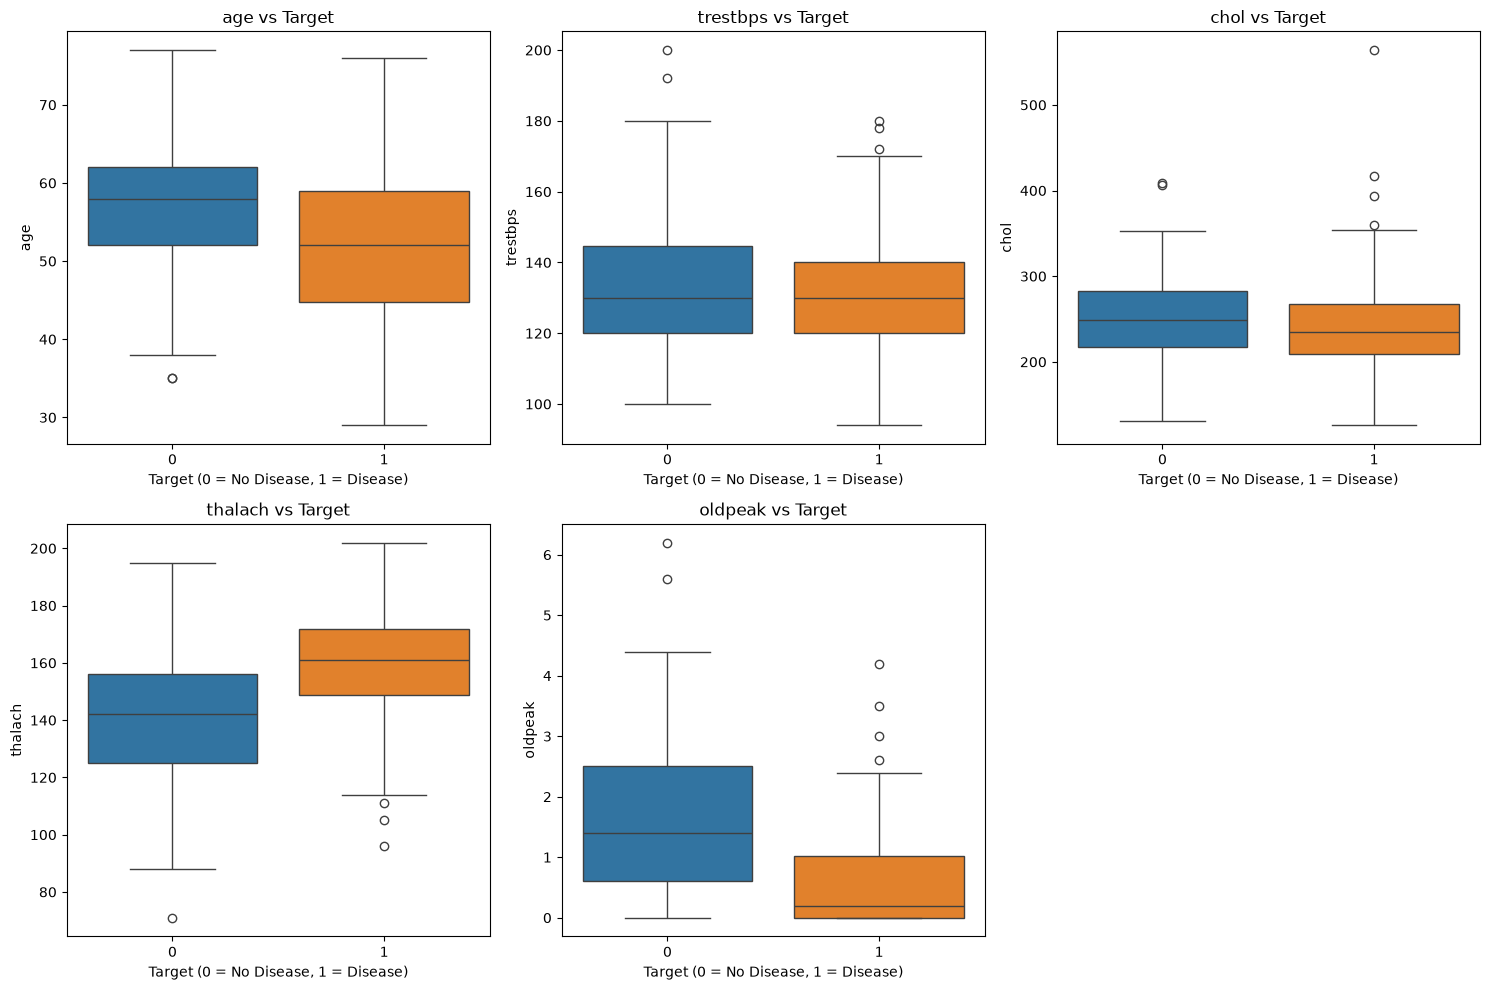

In [15]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df_clean,
        x="target",
        y=col,
        hue="target",
        legend=False
    )

    plt.title(f"{col} vs Target")
    plt.xlabel("Target (0 = No Disease, 1 = Disease)")

plt.tight_layout()
plt.show()

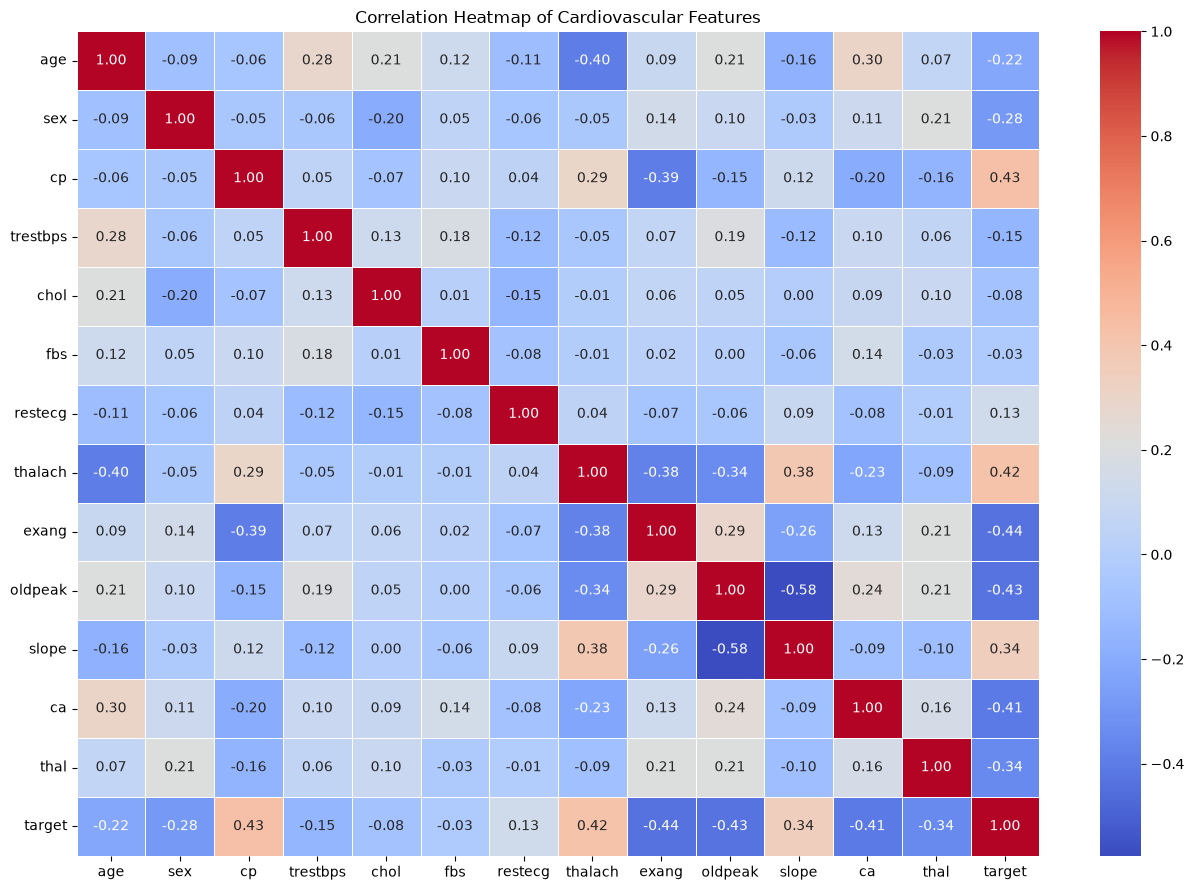

In [16]:
plt.figure(figsize=(13, 9))

correlation = df_clean.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Cardiovascular Features")
plt.tight_layout()
plt.show()

In [17]:
# Outlier detection using IQR

outlier_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

outlier_results = []

for col in outlier_features:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,age,48.00,61.00,13.00,28.500,80.500,0
1,trestbps,120.00,140.00,20.00,90.000,170.000,9
2,chol,211.00,274.75,63.75,115.375,370.375,5
3,thalach,133.25,166.00,32.75,84.125,215.125,1
4,oldpeak,0.00,1.60,1.60,-2.400,4.000,5


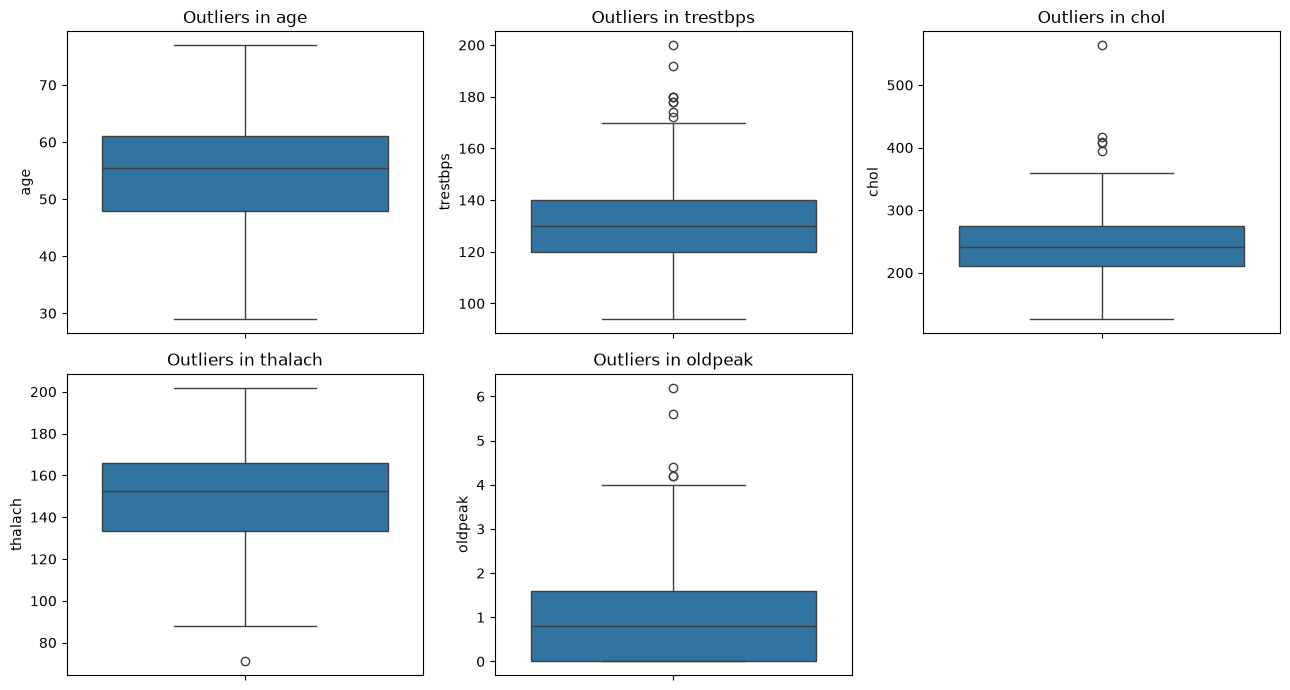

In [18]:
plt.figure(figsize=(13, 7))

for i, col in enumerate(outlier_features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        y=df_clean[col]
    )

    plt.title(f"Outliers in {col}")

plt.tight_layout()
plt.show()

In [19]:
outlier_df.to_csv(
    "../outputs/outlier_analysis.csv",
    index=False
)

print("Outlier analysis saved successfully!")

Outlier analysis saved successfully!


In [20]:
for col in outlier_features:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print(f"\nOutliers in {col}:")
    print(outliers[["age", col, "target"]].to_string(index=True))


Outliers in age:
Empty DataFrame
Columns: [age, age, target]
Index: []

Outliers in trestbps:
     age  trestbps  target
28    55       180       0
44    66       178       0
76    59       174       0
112   64       180       1
124   54       192       0
142   56       200       0
226   52       172       1
248   68       180       0
271   59       178       1

Outliers in chol:
     age  chol  target
104   65   417       1
128   67   564       1
144   56   409       0
183   62   394       1
260   63   407       0

Outliers in thalach:
     age  thalach  target
188   67       71       0

Outliers in oldpeak:
     age  oldpeak  target
6     58      4.4       0
13    51      4.2       0
51    55      5.6       0
63    62      6.2       0
271   59      4.2       1


In [21]:
outlier_records = []

for col in outlier_features:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    )

    temp = df_clean.loc[mask].copy()
    temp["Outlier_Feature"] = col

    outlier_records.append(temp)

outlier_records = pd.concat(
    outlier_records,
    ignore_index=True
)

outlier_records.to_csv(
    "../outputs/outlier_records.csv",
    index=False
)

print("Outlier records saved successfully!")

Outlier records saved successfully!


In [22]:
X = df_clean.drop(columns=["target"])
y = df_clean["target"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (302, 13)
Target Shape: (302,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Features: (241, 13)
Testing Features: (61, 13)

Training Target:
target
1    131
0    110
Name: count, dtype: int64

Testing Target:
target
1    33
0    28
Name: count, dtype: int64


In [24]:
print("Training Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Distribution:
target
1    54.356846
0    45.643154
Name: proportion, dtype: float64

Testing Distribution:
target
1    54.098361
0    45.901639
Name: proportion, dtype: float64


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [26]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 5
Categorical Features: 8


In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

In [28]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (241, 30)
Processed Testing Shape: (61, 30)


In [29]:
print("Training Data Mean:",
      X_train_processed.mean())

print("Training Data Standard Deviation:",
      X_train_processed.std())

print("Missing Values:",
      pd.isnull(X_train_processed).sum())

Training Data Mean: 0.26666666666666666
Training Data Standard Deviation: 0.6018490028422596
Missing Values: 0


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [32]:
y_pred_lr = lr_model.predict(X_test_processed)

y_prob_lr = lr_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions:", y_pred_lr[:10])
print("Actual Values:", y_test.values[:10])

Predictions: [0 1 0 1 1 0 1 0 1 0]
Actual Values: [0 0 0 0 0 0 1 0 1 0]


In [33]:
print("LOGISTIC REGRESSION RESULTS")
print("=" * 40)

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["No Disease", "Disease"],
        zero_division=0
    )
)

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.8360655737704918

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.82      0.82      0.82        28
     Disease       0.85      0.85      0.85        33

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61

ROC-AUC: 0.9047619047619048


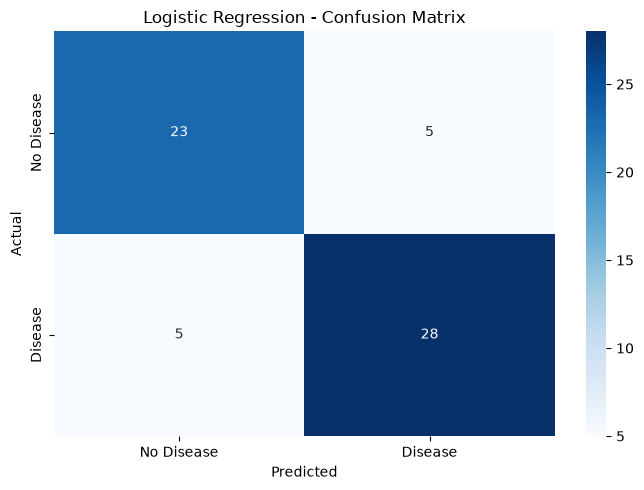

In [34]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()

In [35]:
from sklearn.ensemble import RandomForestClassifier

In [36]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [37]:
y_pred_rf = rf_model.predict(X_test_processed)

y_prob_rf = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions:", y_pred_rf[:10])
print("Actual Values:", y_test.values[:10])

Predictions: [0 1 0 1 1 0 1 0 1 0]
Actual Values: [0 0 0 0 0 0 1 0 1 0]


In [38]:
print("RANDOM FOREST RESULTS")
print("=" * 40)

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["No Disease", "Disease"],
        zero_division=0
    )
)

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

RANDOM FOREST RESULTS
Accuracy: 0.7868852459016393

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.76      0.79      0.77        28
     Disease       0.81      0.79      0.80        33

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61

ROC-AUC: 0.8836580086580087


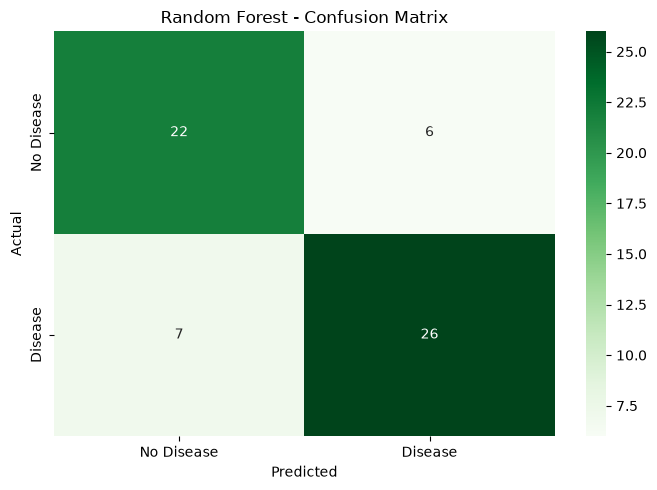

In [39]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.tight_layout()
plt.show()

In [40]:
from xgboost import XGBClassifier

In [41]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(
    X_train_processed,
    y_train
)

print("XGBoost Training Completed!")

XGBoost Training Completed!


In [42]:
y_pred_xgb = xgb_model.predict(X_test_processed)

y_prob_xgb = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions:", y_pred_xgb[:10])
print("Actual Values:", y_test.values[:10])

Predictions: [0 1 0 1 1 0 1 0 1 0]
Actual Values: [0 0 0 0 0 0 1 0 1 0]


In [43]:
print("XGBOOST RESULTS")
print("=" * 40)

print("Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=["No Disease", "Disease"],
        zero_division=0
    )
)

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgb))

XGBOOST RESULTS
Accuracy: 0.7868852459016393

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.76      0.79      0.77        28
     Disease       0.81      0.79      0.80        33

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61

ROC-AUC: 0.8625541125541126


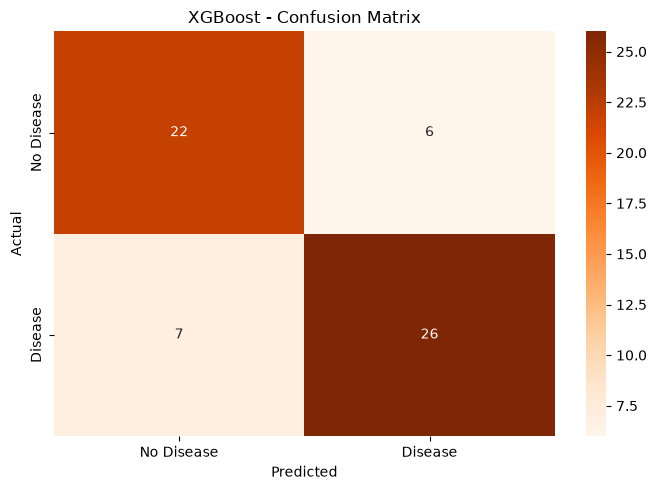

In [44]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost - Confusion Matrix")

plt.tight_layout()
plt.show()


In [45]:
from sklearn.svm import SVC

In [46]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_processed,
    y_train
)

print("SVM Training Completed!")

SVM Training Completed!


c:\Users\Ayush Saha\OneDrive\Desktop\Explainable_CVD_Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [47]:
y_pred_svm = svm_model.predict(X_test_processed)

y_prob_svm = svm_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions:", y_pred_svm[:10])
print("Actual Values:", y_test.values[:10])

Predictions: [0 1 0 1 1 0 1 0 1 0]
Actual Values: [0 0 0 0 0 0 1 0 1 0]


In [48]:
print("SVM RESULTS")
print("=" * 40)

print("Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=["No Disease", "Disease"],
        zero_division=0
    )
)

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_svm))

SVM RESULTS
Accuracy: 0.7868852459016393

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.76      0.79      0.77        28
     Disease       0.81      0.79      0.80        33

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61

ROC-AUC: 0.8787878787878788


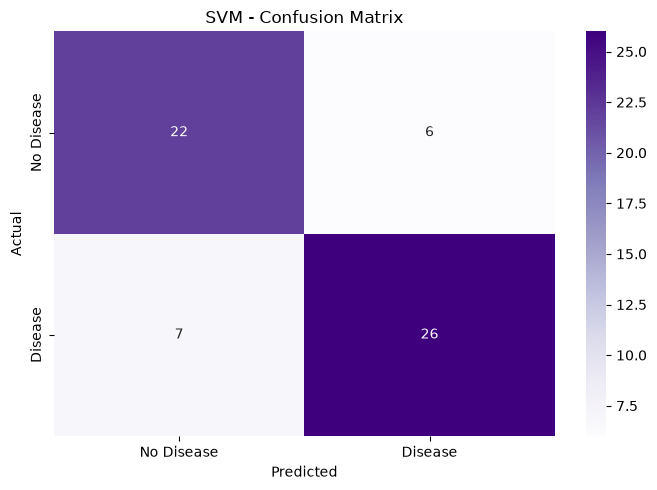

In [49]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM - Confusion Matrix")

plt.tight_layout()
plt.show()

In [50]:
results = {
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_svm)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb),
        roc_auc_score(y_test, y_prob_svm)
    ]
}

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  ROC-AUC
0  Logistic Regression    0.8361   0.9048
1        Random Forest    0.7869   0.8837
2              XGBoost    0.7869   0.8626
3                  SVM    0.7869   0.8788


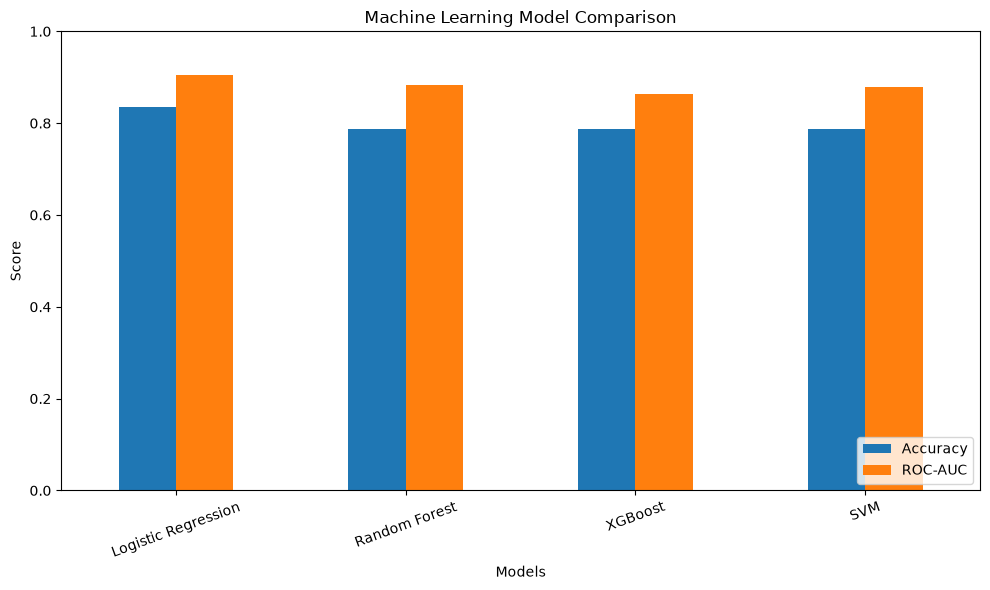

In [51]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [52]:
results_df.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [53]:
import shap

print("SHAP Version:", shap.__version__)

SHAP Version: 0.54.1


In [54]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(
    X_test_processed
)

print("SHAP Values Generated Successfully!")
print("SHAP Shape:", np.array(shap_values).shape)

SHAP Values Generated Successfully!
SHAP Shape: (61, 30)


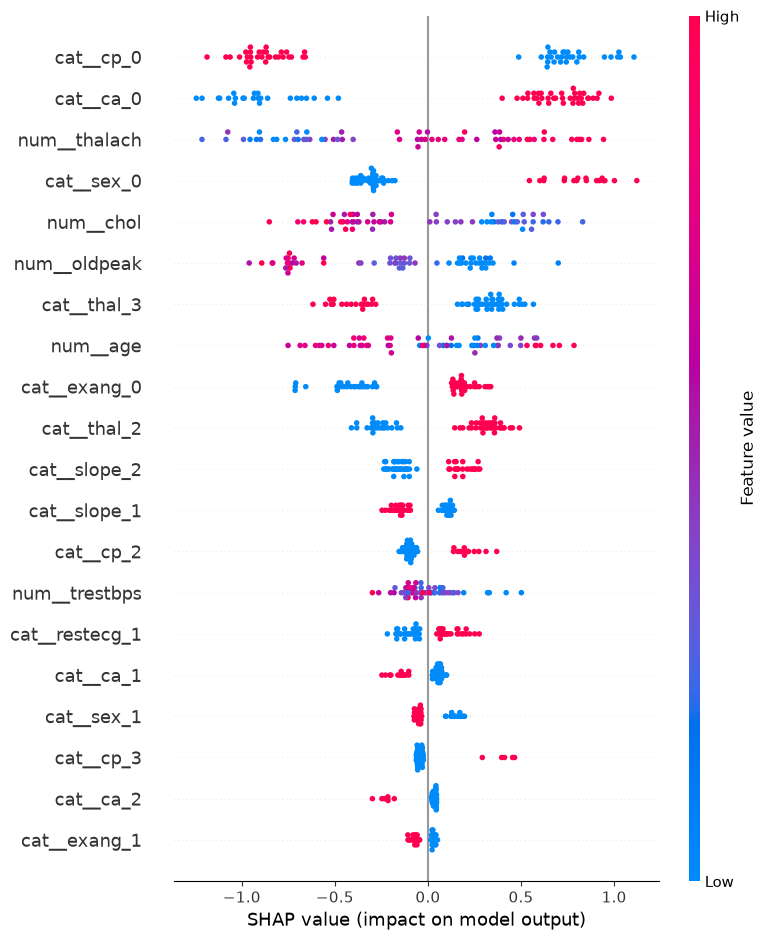

In [55]:
feature_names = (
    preprocessor.get_feature_names_out()
)

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names
)

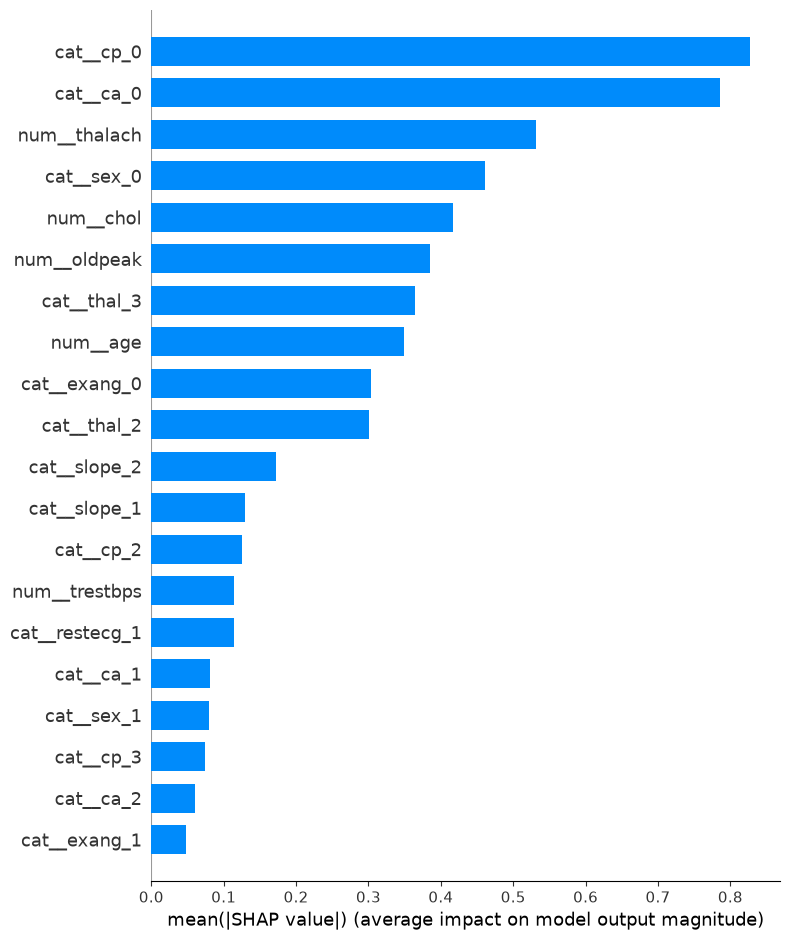

In [56]:
shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar"
)

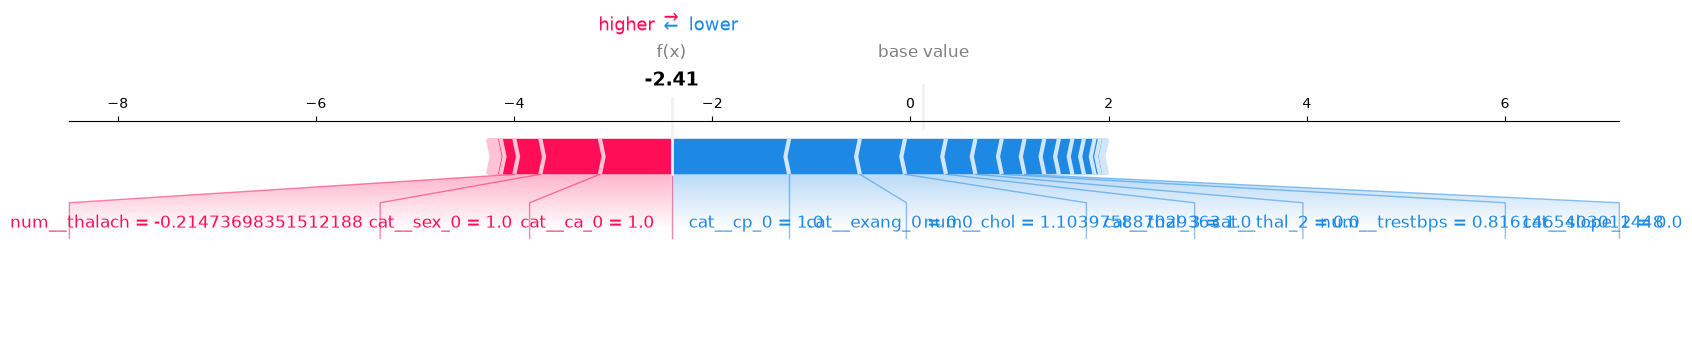

In [57]:
shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    X_test_processed[0],
    feature_names=feature_names,
    matplotlib=True
)

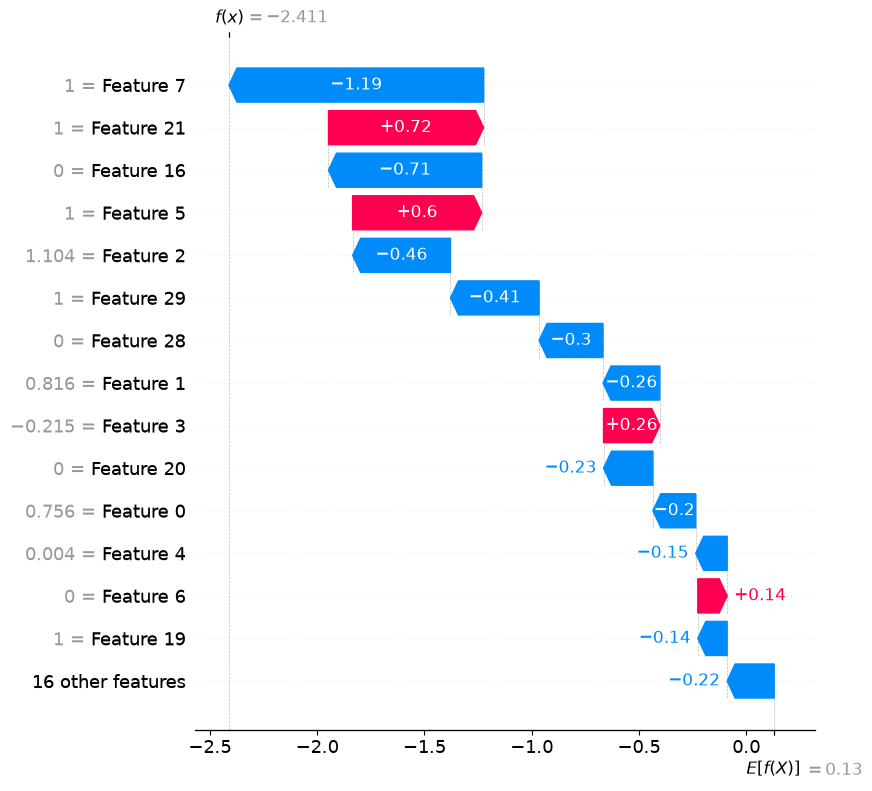

In [58]:
shap_explanation = explainer(
    X_test_processed
)

shap.plots.waterfall(
    shap_explanation[0],
    max_display=15
)

In [59]:
import os

os.makedirs("../outputs/shap", exist_ok=True)

plt.figure()
shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    show=False
)
plt.savefig(
    "../outputs/shap/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

plt.figure()
shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)
plt.savefig(
    "../outputs/shap/shap_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("SHAP plots saved successfully!")

SHAP plots saved successfully!


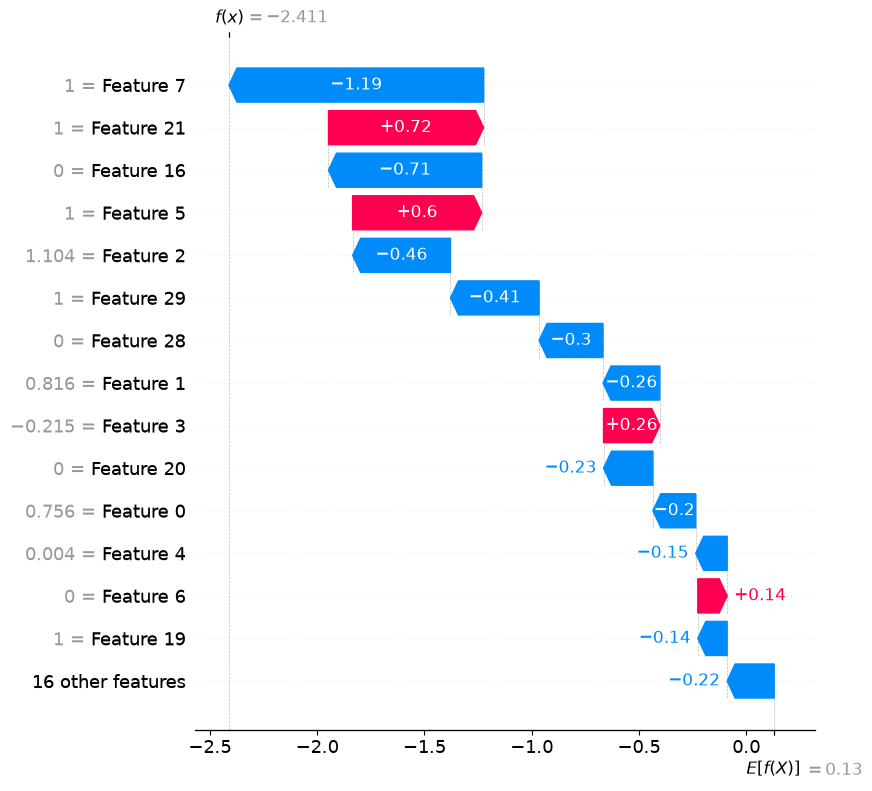

In [60]:
# Generate SHAP explanation
shap_explanation = explainer(X_test_processed)

# Display waterfall plot
shap.plots.waterfall(
    shap_explanation[0],
    max_display=15
)

In [61]:
plt.savefig(
    "../outputs/shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [62]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("../outputs/lime", exist_ok=True)

feature_names = preprocessor.get_feature_names_out()

lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=list(feature_names),
    class_names=["No Disease", "Disease"],
    mode="classification",
    discretize_continuous=True
)

print("LIME Explainer Created Successfully!")

LIME Explainer Created Successfully!


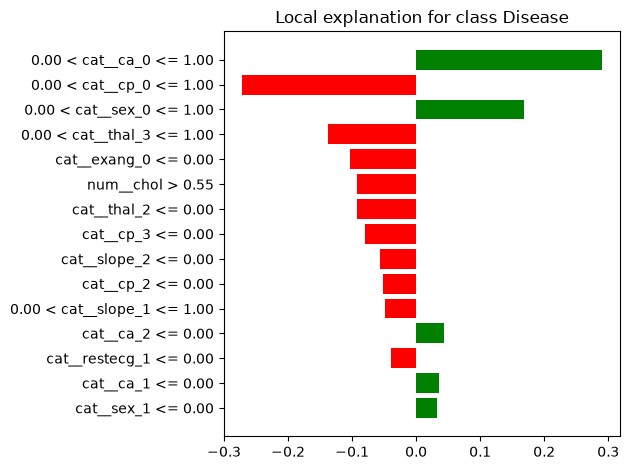

In [64]:
import matplotlib.pyplot as plt

fig = lime_exp.as_pyplot_figure(label=1)

plt.tight_layout()
plt.show()

In [65]:
import os

os.makedirs("../outputs/lime", exist_ok=True)

fig.savefig(
    "../outputs/lime/lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

print("LIME Explanation Saved Successfully!")

LIME Explanation Saved Successfully!


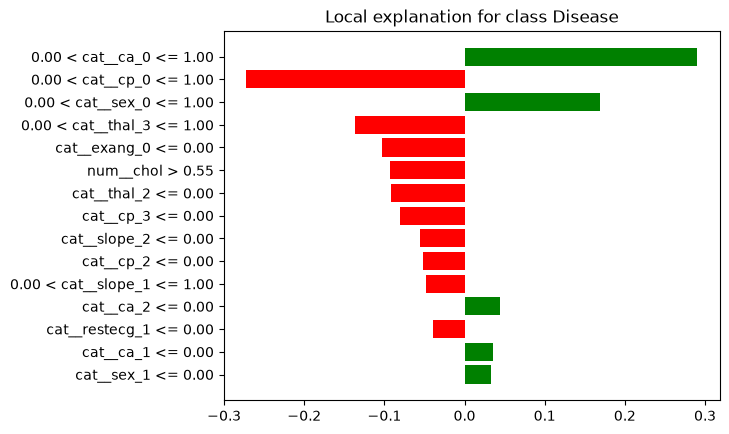

In [66]:
fig = lime_exp.as_pyplot_figure(label=1)

fig.savefig(
    "../outputs/lime/lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42,
        class_weight="balanced"
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression    0.8462     0.8589  0.8775    0.8620   0.9278
1        Random Forest    0.8546     0.8690  0.8778    0.8697   0.9081
2              XGBoost    0.8296     0.8426  0.8544    0.8431   0.9025
3                  SVM    0.8669     0.8574  0.9157    0.8822   0.9174


In [68]:
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    lr_pipeline,
    param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

Best Cross-Validation ROC-AUC:
0.9278295778295778


FINAL MODEL RESULTS
Accuracy: 0.8360655737704918

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.82      0.82      0.82        28
     Disease       0.85      0.85      0.85        33

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61

ROC-AUC: 0.9047619047619048


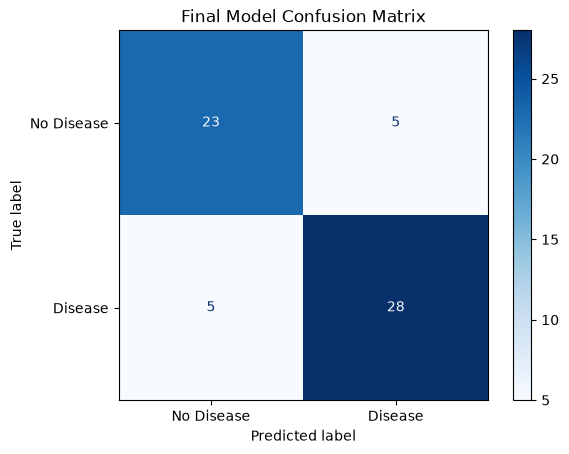

In [69]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

final_model = grid_search.best_estimator_

y_final_pred = final_model.predict(X_test)

y_final_prob = final_model.predict_proba(X_test)[:, 1]

print("FINAL MODEL RESULTS")
print("=" * 40)

print("Accuracy:",
      accuracy_score(y_test, y_final_pred))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_final_pred,
    target_names=["No Disease", "Disease"]
))

print("ROC-AUC:",
      roc_auc_score(y_test, y_final_prob))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_final_pred,
    display_labels=["No Disease", "Disease"],
    cmap="Blues"
)

plt.title("Final Model Confusion Matrix")
plt.show()

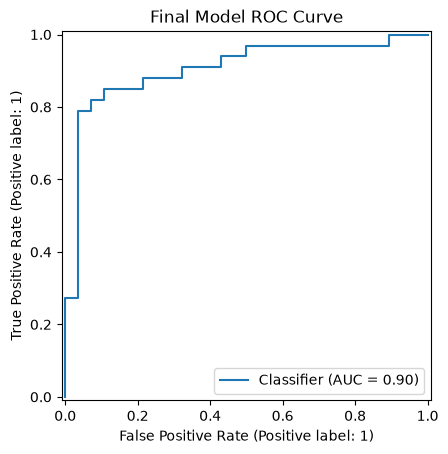

In [70]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_final_prob
)

plt.title("Final Model ROC Curve")
plt.show()

In [71]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/final_cvd_model.pkl"
)

print("Final Model Saved Successfully!")

Final Model Saved Successfully!


In [73]:
import lime
import lime
from lime.lime_tabular import LimeTabularExplainer

print("LIME Installed Successfully!")
print("LIME Module Location:", lime.__file__)

LIME Installed Successfully!
LIME Module Location: c:\Users\Ayush Saha\OneDrive\Desktop\Explainable_CVD_Prediction\.venv\Lib\site-packages\lime\__init__.py


In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from lime.lime_tabular import LimeTabularExplainer

print("LIME Libraries Imported Successfully!")

LIME Libraries Imported Successfully!


In [76]:
feature_names = list(X_train.columns)

categorical_indices = [
    feature_names.index(col)
    for col in categorical_features
]

categorical_names = {
    feature_names.index(col):
    sorted(X_train[col].astype(int).unique().tolist())
    for col in categorical_features
}

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=feature_names,
    class_names=["No Disease", "Disease"],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME Explainer Created Successfully!")
print("Number of Features:", len(feature_names))

LIME Explainer Created Successfully!
Number of Features: 13


In [77]:
def lime_predict(data):

    data = pd.DataFrame(
        data,
        columns=feature_names
    )

    for col in categorical_features:
        data[col] = data[col].round().astype(int)

    processed_data = preprocessor.transform(data)

    return xgb_model.predict_proba(processed_data)


print("LIME Prediction Function Created Successfully!")

LIME Prediction Function Created Successfully!


In [78]:
patient_index = 0

patient_data = X_test.iloc[patient_index].to_numpy()

lime_exp = lime_explainer.explain_instance(
    data_row=patient_data,
    predict_fn=lime_predict,
    num_features=13,
    num_samples=5000,
    labels=(1,)
)

print("LIME Explanation Generated Successfully!")

print("\nActual Target:",
      y_test.iloc[patient_index])

print("Predicted Target:",
      xgb_model.predict(
          X_test_processed[patient_index].reshape(1, -1)
      )[0])

print("\nLIME Feature Contributions:")

print(lime_exp.as_list(label=1))

LIME Explanation Generated Successfully!

Actual Target: 0
Predicted Target: 0

LIME Feature Contributions:
[('ca=0', 0.2943922031050982), ('cp=0', -0.28064387725254186), ('thal=3', -0.21215323692863422), ('sex=0', 0.20411225022826987), ('exang=1', -0.09973112326658788), ('chol > 277.00', -0.09776925106043943), ('slope=1', -0.08708471484526618), ('restecg=0', -0.0441645102113103), ('0.60 < oldpeak <= 1.60', -0.03544369382698446), ('fbs=0', -0.030292543314050575), ('trestbps > 140.00', -0.025597778305972603), ('138.00 < thalach <= 154.00', 0.019167946289759468), ('age > 60.00', 0.01824293822671003)]


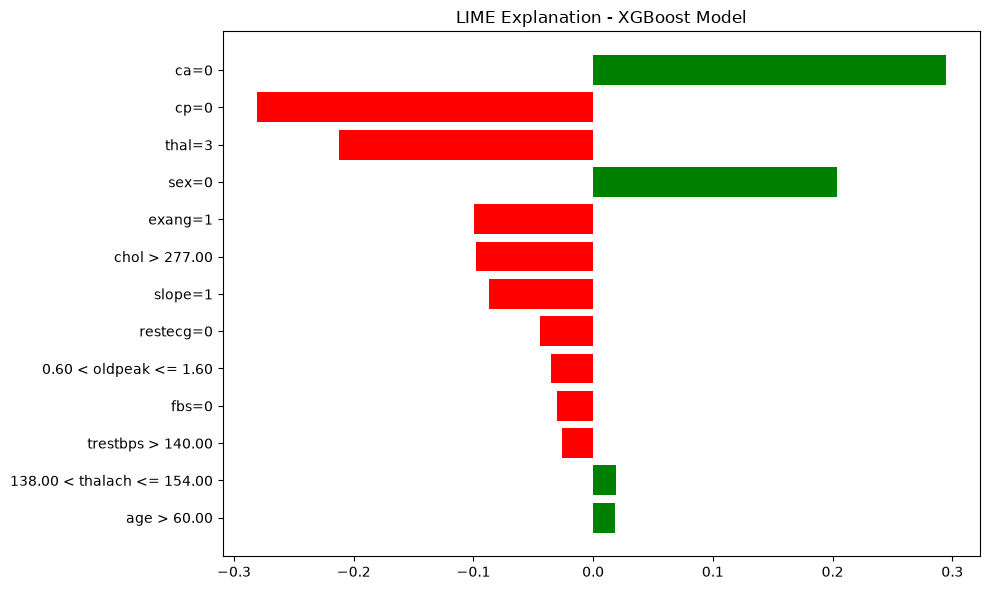

In [79]:
fig = lime_exp.as_pyplot_figure(label=1)

fig.set_size_inches(10, 6)

plt.title("LIME Explanation - XGBoost Model")

plt.tight_layout()

plt.show()

In [80]:
os.makedirs("../outputs/lime", exist_ok=True)

fig.savefig(
    "../outputs/lime/lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

print("LIME Explanation Saved Successfully!")

LIME Explanation Saved Successfully!


In [81]:
os.makedirs("../outputs/lime", exist_ok=True)

for i in range(5):

    exp = lime_explainer.explain_instance(
        X_test.iloc[i].to_numpy(),
        lime_predict,
        num_features=13,
        num_samples=5000,
        labels=(1,)
    )

    fig = exp.as_pyplot_figure(label=1)

    fig.savefig(
        f"../outputs/lime/patient_{i+1}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

print("Five Patient Explanations Saved Successfully!")

Five Patient Explanations Saved Successfully!


In [82]:
# Original feature names
feature_names = list(X_train.columns)

# Identify categorical feature positions
categorical_indices = [
    feature_names.index(col)
    for col in categorical_features
]

# Define categorical values
categorical_names = {
    feature_names.index(col):
    sorted(X_train[col].astype(int).unique().tolist())
    for col in categorical_features
}

# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=feature_names,
    class_names=["No Disease", "Disease"],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME Explainer Created Successfully!")
print("Number of Features:", len(feature_names))
print("Categorical Features:", len(categorical_indices))

LIME Explainer Created Successfully!
Number of Features: 13
Categorical Features: 8


In [83]:
def lime_predict(data):

    data = pd.DataFrame(
        data,
        columns=feature_names
    )

    for col in categorical_features:
        data[col] = data[col].round().astype(int)

    processed_data = preprocessor.transform(data)

    return xgb_model.predict_proba(processed_data)


print("LIME Prediction Function Created Successfully!")

LIME Prediction Function Created Successfully!


In [84]:
patient_index = 0

patient_data = X_test.iloc[patient_index].to_numpy()

lime_exp = lime_explainer.explain_instance(
    data_row=patient_data,
    predict_fn=lime_predict,
    num_features=13,
    num_samples=5000,
    labels=(1,)
)

print("LIME Explanation Generated Successfully!")

print("\nActual Target:",
      y_test.iloc[patient_index])

print("Predicted Target:",
      xgb_model.predict(
          X_test_processed[patient_index].reshape(1, -1)
      )[0])

print("\nFeature Contributions:")

print(lime_exp.as_list(label=1))

LIME Explanation Generated Successfully!

Actual Target: 0
Predicted Target: 0

Feature Contributions:
[('ca=0', 0.2943922031050982), ('cp=0', -0.28064387725254186), ('thal=3', -0.21215323692863422), ('sex=0', 0.20411225022826987), ('exang=1', -0.09973112326658788), ('chol > 277.00', -0.09776925106043943), ('slope=1', -0.08708471484526618), ('restecg=0', -0.0441645102113103), ('0.60 < oldpeak <= 1.60', -0.03544369382698446), ('fbs=0', -0.030292543314050575), ('trestbps > 140.00', -0.025597778305972603), ('138.00 < thalach <= 154.00', 0.019167946289759468), ('age > 60.00', 0.01824293822671003)]


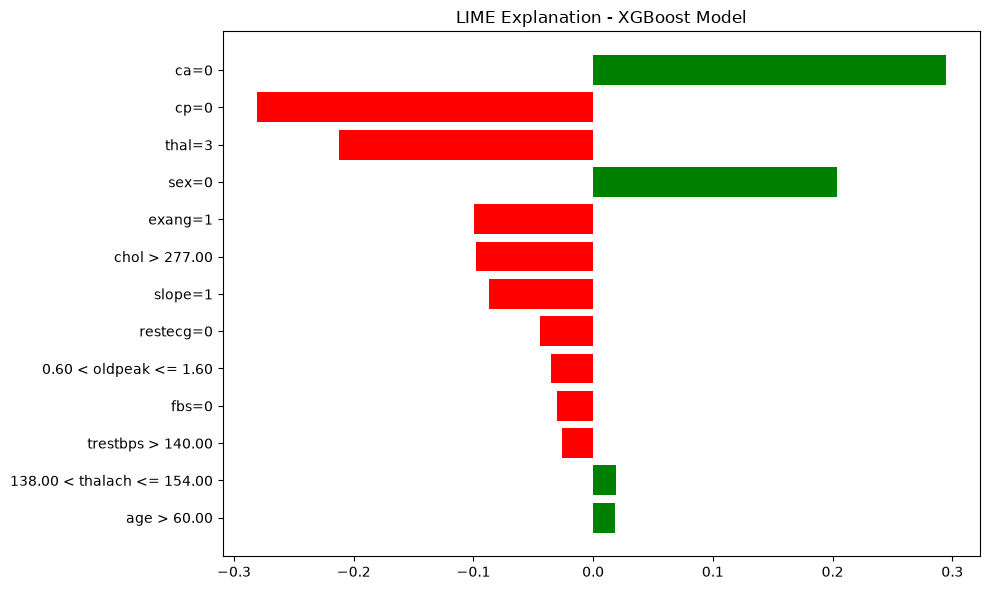

In [85]:
fig = lime_exp.as_pyplot_figure(label=1)

fig.set_size_inches(10, 6)

plt.title("LIME Explanation - XGBoost Model")

plt.tight_layout()

plt.show()

In [86]:
os.makedirs("../outputs/lime", exist_ok=True)

fig.savefig(
    "../outputs/lime/lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

print("LIME Explanation Saved Successfully!")

LIME Explanation Saved Successfully!


In [87]:

import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

# Create output folder
os.makedirs("../outputs/patient_explanations", exist_ok=True)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert SHAP values to NumPy format
sv = shap_values.values if hasattr(shap_values, "values") else shap_values

if isinstance(sv, list):
    sv = sv[1]

if sv.ndim == 3:
    sv = sv[:, :, 1]

# Initialize LIME
lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=list(feature_names),
    class_names=["No Disease", "Disease"],
    mode="classification",
    random_state=42
)

print("LIME Explainer Initialized!")
print("Number of test patients:", len(X_test_processed))


LIME Explainer Initialized!
Number of test patients: 61


In [88]:

comparison_results = []

# Select first five test patients
patient_indices = range(5)

for patient_no, i in enumerate(patient_indices, start=1):

    patient_data = np.asarray(X_test_processed[i]).ravel()

    # XGBoost prediction
    prediction = int(xgb_model.predict(
        X_test_processed[i:i+1]
    )[0])

    probability = xgb_model.predict_proba(
        X_test_processed[i:i+1]
    )[0][1]

    # SHAP explanation
    shap_importance = sv[i]

    shap_top = np.argsort(
        np.abs(shap_importance)
    )[::-1][:10]

    # LIME explanation
    lime_exp = lime_explainer.explain_instance(
        data_row=patient_data,
        predict_fn=xgb_model.predict_proba,
        num_features=10,
        top_labels=2
    )

    lime_map = dict(lime_exp.as_map()[1])

    # Save LIME HTML explanation
    lime_exp.save_to_file(
        f"../outputs/patient_explanations/patient_{patient_no}_lime.html"
    )

    # SHAP vs LIME comparison
    for idx in sorted(set(shap_top) | set(lime_map)):

        comparison_results.append({
            "Patient": patient_no,
            "Feature": feature_names[idx],
            "SHAP_Value": shap_importance[idx],
            "LIME_Weight": lime_map.get(idx, 0),
            "Prediction": prediction,
            "Disease_Probability": probability
        })

    print(f"Patient {patient_no} explained successfully!")

print("\nAll five patient explanations generated!")


Patient 1 explained successfully!
Patient 2 explained successfully!
Patient 3 explained successfully!
Patient 4 explained successfully!
Patient 5 explained successfully!

All five patient explanations generated!


In [89]:

comparison_df = pd.DataFrame(comparison_results)

comparison_df.to_csv(
    "../outputs/patient_explanations/shap_lime_comparison.csv",
    index=False
)

print("SHAP vs LIME COMPARISON")
print("=" * 60)

display(comparison_df.head(30))

print("\nSaved successfully!")


SHAP vs LIME COMPARISON


,Patient,Feature,SHAP_Value,LIME_Weight,Prediction,Disease_Probability
0,1,num__trestbps,-0.264792,0.000000,0,0.082319
1,1,num__chol,-0.456115,-0.088331,0,0.082319
2,1,num__thalach,0.262334,0.000000,0,0.082319
3,1,cat__sex_0,0.601170,0.168571,0,0.082319
4,1,cat__cp_0,-1.186769,-0.265480,0,0.082319
5,1,cat__cp_2,-0.115949,-0.055050,0,0.082319
6,1,cat__cp_3,-0.054858,-0.057340,0,0.082319
7,1,cat__exang_0,-0.713696,-0.095284,0,0.082319
8,1,cat__slope_2,-0.230054,-0.051682,0,0.082319
9,1,cat__ca_0,0.722907,0.292051,0,0.082319



Saved successfully!


In [90]:

# Get SHAP base value
base = explainer.expected_value

if isinstance(base, (list, np.ndarray)):
    base = np.asarray(base).reshape(-1)[-1]

for patient_no, i in enumerate(range(5), start=1):

    explanation = shap.Explanation(
        values=sv[i],
        base_values=float(base),
        data=np.asarray(X_test_processed[i]),
        feature_names=list(feature_names)
    )

    shap.plots.waterfall(
        explanation,
        max_display=10,
        show=False
    )

    plt.savefig(
        f"../outputs/patient_explanations/patient_{patient_no}_shap.png",
        bbox_inches="tight",
        dpi=150
    )

    plt.close()

print("Five SHAP waterfall plots saved successfully!")

Five SHAP waterfall plots saved successfully!


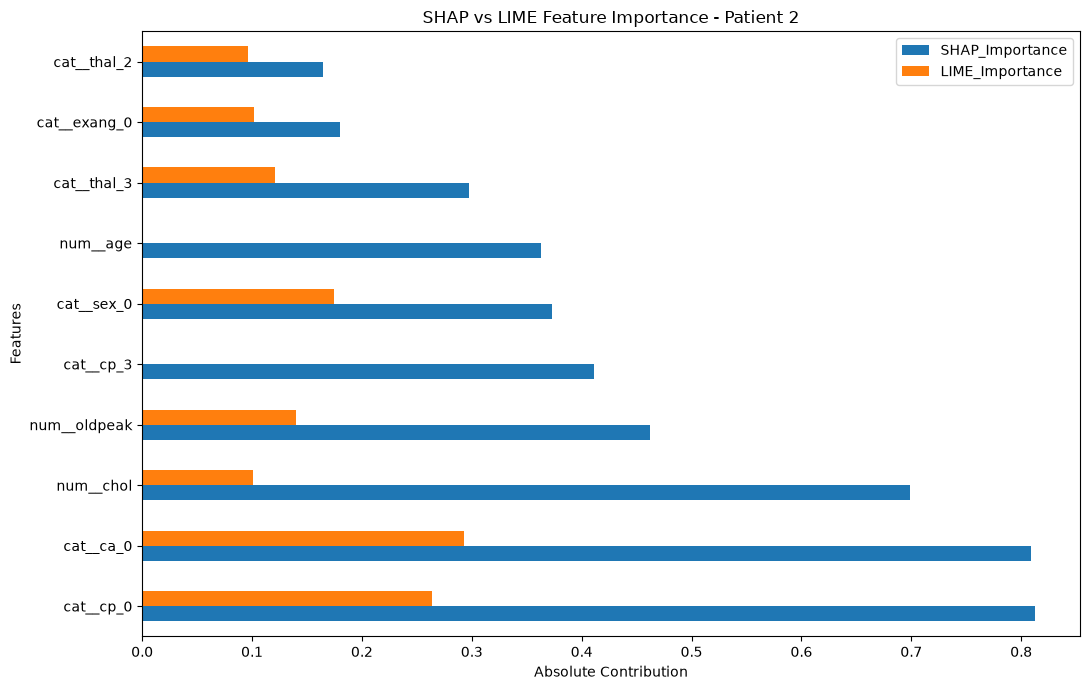

In [91]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load comparison results
comparison_df = pd.read_csv(
    "../outputs/patient_explanations/shap_lime_comparison.csv"
)

# Select patient 2
patient_data = comparison_df[
    comparison_df["Patient"] == 2
].copy()

# Compare absolute feature contributions
patient_data["SHAP_Importance"] = (
    patient_data["SHAP_Value"].abs()
)

patient_data["LIME_Importance"] = (
    patient_data["LIME_Weight"].abs()
)

# Get top 10 SHAP features
patient_data = patient_data.nlargest(
    10, "SHAP_Importance"
)

# Plot
plot_data = patient_data.set_index("Feature")[
    ["SHAP_Importance", "LIME_Importance"]
]

plot_data.plot(
    kind="barh",
    figsize=(11, 7)
)

plt.title("SHAP vs LIME Feature Importance - Patient 2")
plt.xlabel("Absolute Contribution")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(
    "../outputs/patient_explanations/patient_2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [93]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

Current directory: c:\Users\Ayush Saha\OneDrive\Desktop\Explainable_CVD_Prediction\notebooks
Files here: ['01_data_analysis.ipynb']


In [94]:
import joblib
import os

model_path = "../models/final_cvd_model.pkl"

print("File exists:", os.path.exists(model_path))

model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(model))

File exists: True
Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [95]:
print("Pipeline steps:")

for step_name, step_object in model.named_steps.items():
    print(f"{step_name}: {type(step_object)}")

print("\nExpected input features:")

if hasattr(model, "feature_names_in_"):
    print(model.feature_names_in_)

print("\nPipeline classes:")

if hasattr(model, "classes_"):
    print(model.classes_)

Pipeline steps:
preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
classifier: <class 'sklearn.linear_model._logistic.LogisticRegression'>

Expected input features:
['age' 'sex' 'cp' 'trestbps' 'chol' 'fbs' 'restecg' 'thalach' 'exang'
 'oldpeak' 'slope' 'ca' 'thal']

Pipeline classes:
[0 1]


In [97]:
import joblib
import numpy as np
import os

# Load the transformed training data
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

X_train_transformed = preprocessor.transform(X_train)

# Get transformed feature names
transformed_features = preprocessor.get_feature_names_out()

# Create model package
model_package = {
    "pipeline": model,
    "X_train_transformed": np.asarray(X_train_transformed),
    "feature_names": list(model.feature_names_in_),
    "transformed_feature_names": list(transformed_features),
    "classes": list(model.classes_)
}

# Save package
os.makedirs("../models", exist_ok=True)

joblib.dump(
    model_package,
    "../models/cvd_website_bundle.joblib"
)

print("Website model package saved successfully!")
print("Original features:", len(model.feature_names_in_))
print("Transformed features:", len(transformed_features))
print("Training samples:", len(X_train_transformed))

Website model package saved successfully!
Original features: 13
Transformed features: 30
Training samples: 241
